<a href="https://colab.research.google.com/github/vishwa24816/Stock-price-prediction-via-ML-Models/blob/main/Machine_learning_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(6538, 1) 2000-01-03 -> 2025-12-30


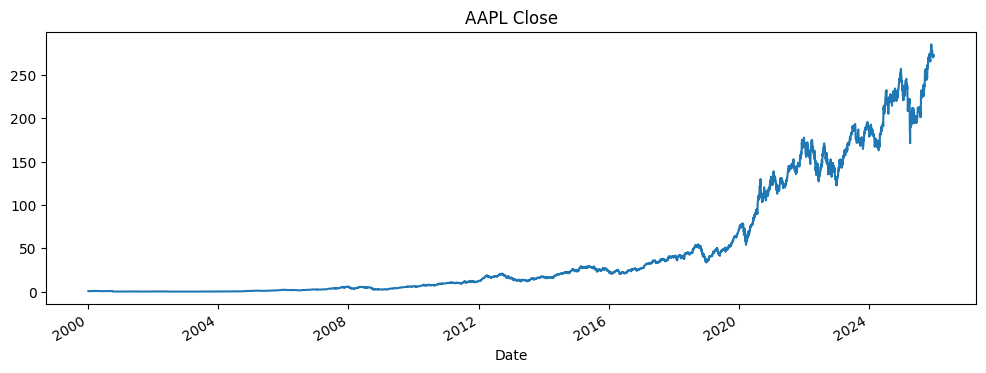

In [ ]:
# !pip install -q yfinance xgboost tensorflow scikit-learn matplotlib

import numpy as np, pandas as pd, matplotlib.pyplot as plt, yfinance as yf
import warnings; warnings.filterwarnings("ignore")

TICKER = "AAPL"   # change to any stock

raw = yf.download(TICKER, start="2000-01-01", end="2025-12-31", interval="1d", auto_adjust=True, progress=False)
raw.columns = raw.columns.get_level_values(0)
df = raw[["Close"]].copy()
print(df.shape, df.index.min().date(), "->", df.index.max().date())
df["Close"].plot(figsize=(12,4), title=f"{TICKER} Close"); plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

df["ret"] = np.log(df["Close"]).diff()
for l in range(1, 11):
    df[f"lag{l}"] = df["ret"].shift(l-1)
for w in (5, 10, 20):
    df[f"mean{w}"] = df["ret"].rolling(w).mean()
    df[f"std{w}"]  = df["ret"].rolling(w).std()
for w in (10, 20, 50):
    df[f"sma_ratio{w}"] = df["Close"] / df["Close"].rolling(w).mean() - 1

df["target"]    = df["ret"].shift(-1)
df["NextClose"] = df["Close"].shift(-1)
df = df.dropna()

FEATS = [c for c in df.columns if c not in ("Close", "ret", "target", "NextClose")]
is_train = df.index < "2020-01-01"
train, test = df[is_train], df[~is_train]

scaler = StandardScaler().fit(train[FEATS])
Xtr, Xte = scaler.transform(train[FEATS]), scaler.transform(test[FEATS])
ytr = train["target"].values

actual = test["NextClose"]
preds = {}
to_price = lambda r: pd.Series(test["Close"].values * np.exp(r), index=test.index)
print("Train:", train.shape, "Test:", test.shape)

Train: (4982, 23) Test: (1506, 23)


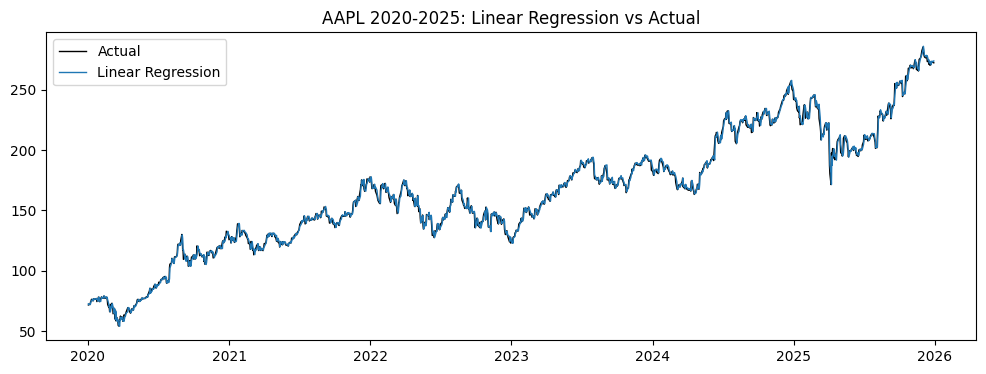

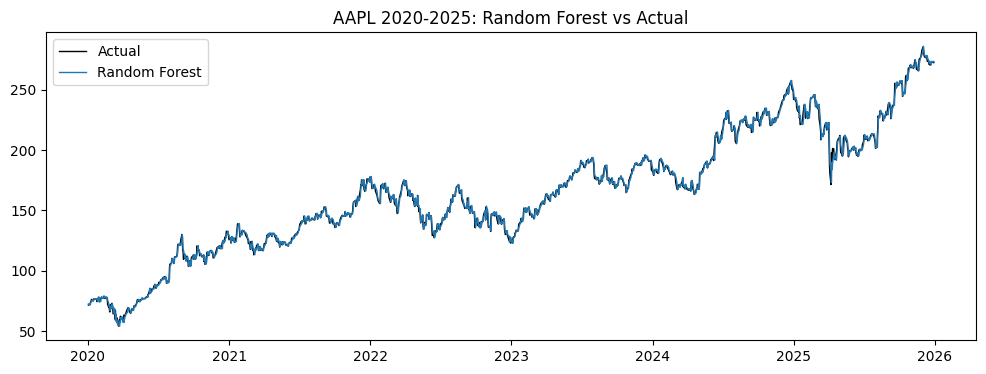

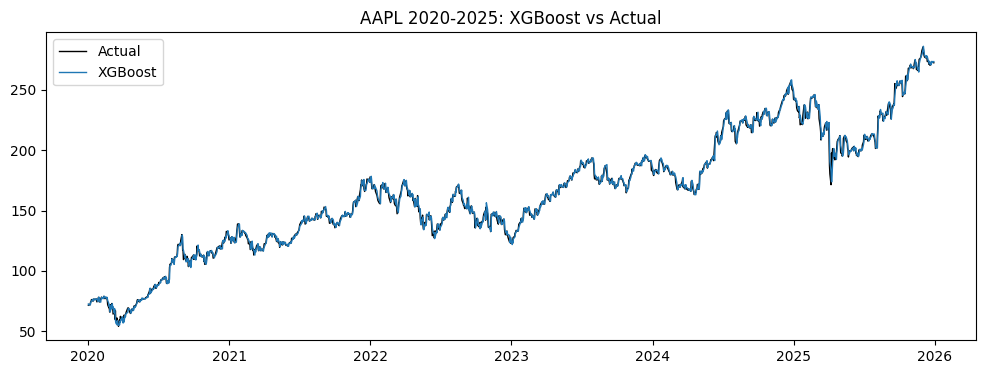

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=42),
}

for name, m in models.items():
    m.fit(Xtr, ytr)
    preds[name] = to_price(m.predict(Xte))
    plt.figure(figsize=(12,4))
    plt.plot(actual, label="Actual", color="black", lw=1)
    plt.plot(preds[name], label=name, lw=1)
    plt.title(f"{TICKER} 2020-2025: {name} vs Actual"); plt.legend(); plt.show()

Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - loss: 0.0076 - val_loss: 3.7801e-04
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 0.0022 - val_loss: 4.1470e-04
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0018 - val_loss: 3.7455e-04
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0013 - val_loss: 3.2964e-04
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0012 - val_loss: 3.3825e-04
Epoch 6/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0012 - val_loss: 3.4173e-04
Epoch 7/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 0.0011 - val_loss: 3.1451e-04
Epoch 8/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 9.9042e-04 - val_loss: 3.1254e-04
Epoch 9/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - loss: 9.7024e-04 - val_loss: 3.1298e-04
Epoch 10/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 9.2161e-04 - val_loss: 3.1228e-04
Epoch 11/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 55ms/step - loss: 8.6893e-04 - val_loss: 3.0899e-04
Epo

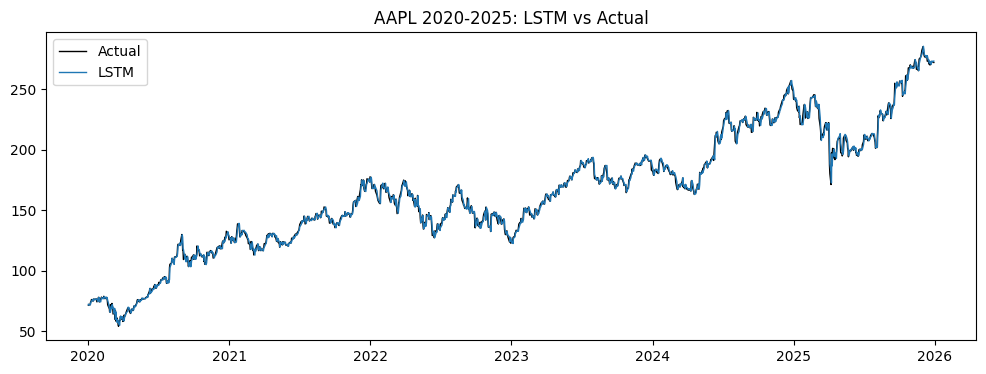

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models as km, callbacks

tf.random.set_seed(42); np.random.seed(42)
WIN = 30
Xall = scaler.transform(df[FEATS]); yall = df["target"].values
Xs = np.array([Xall[i-WIN+1:i+1] for i in range(WIN-1, len(df))])
ys = yall[WIN-1:]
dates = df.index[WIN-1:]
tr_mask = dates < "2020-01-01"

lstm = km.Sequential([
    layers.Input(shape=(WIN, len(FEATS))),
    layers.LSTM(64, return_sequences=True), layers.Dropout(0.2),
    layers.LSTM(32), layers.Dropout(0.2),
    layers.Dense(1),
])
lstm.compile(optimizer="adam", loss="mse")
lstm.fit(Xs[tr_mask], ys[tr_mask], epochs=50, batch_size=64, validation_split=0.1, shuffle=False,
         callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=1)

r = pd.Series(lstm.predict(Xs[~tr_mask]).flatten(), index=dates[~tr_mask]).reindex(test.index).values
preds["LSTM"] = to_price(r)

plt.figure(figsize=(12,4))
plt.plot(actual, label="Actual", color="black", lw=1)
plt.plot(preds["LSTM"], label="LSTM", lw=1)
plt.title(f"{TICKER} 2020-2025: LSTM vs Actual"); plt.legend(); plt.show()

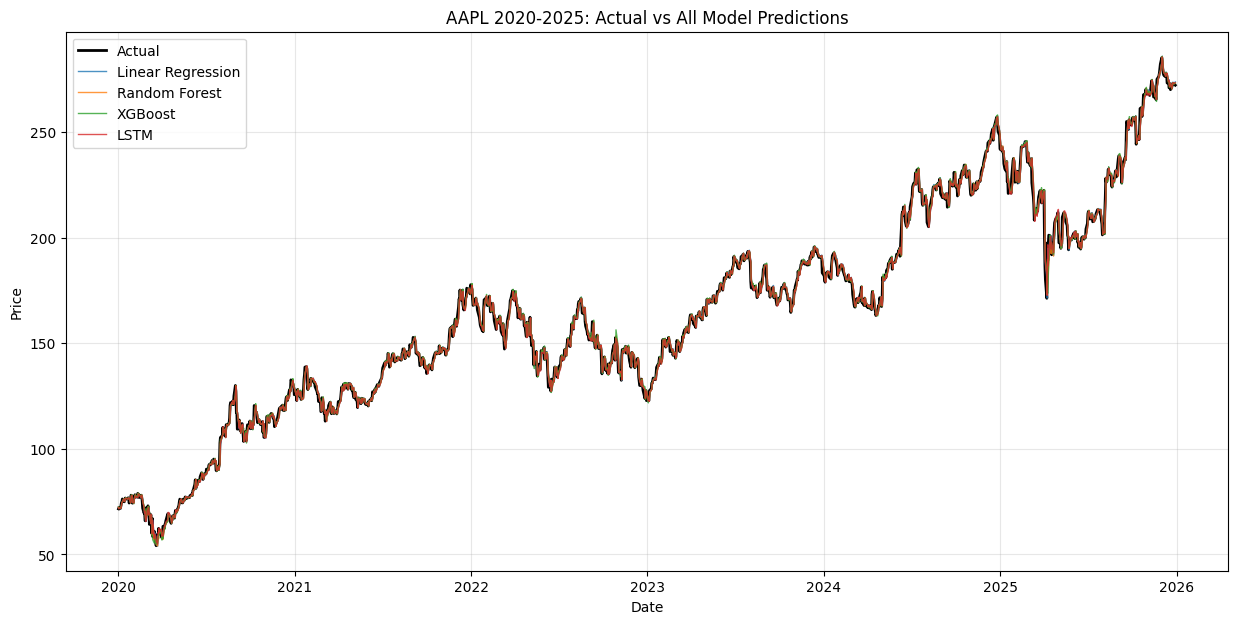

,RMSE,MAE,MAPE %,Direction Acc %
Model,,,,
LSTM,3.005,2.134,1.394,51.328
Linear Regression,3.007,2.125,1.389,53.254
Random Forest,3.009,2.120,1.388,53.054
XGBoost,3.069,2.159,1.411,52.125


Closest to actual price (lowest RMSE): LSTM
Best direction accuracy: Linear Regression


In [31]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.figure(figsize=(15,7))
plt.plot(actual, label="Actual", color="black", lw=2)
for name, p in preds.items():
    plt.plot(p, label=name, lw=1, alpha=0.8)
plt.title(f"{TICKER} 2020-2025: Actual vs All Model Predictions"); plt.xlabel("Date"); plt.ylabel("Price")
plt.legend(); plt.grid(alpha=0.3); plt.show()

rows = []
for name, p in preds.items():
    rmse = np.sqrt(mean_squared_error(actual, p))
    mae  = mean_absolute_error(actual, p)
    mape = np.mean(np.abs((actual - p) / actual)) * 100
    dir_acc = np.mean(np.sign(p.values - test["Close"].values) == np.sign(actual.values - test["Close"].values)) * 100
    rows.append([name, rmse, mae, mape, dir_acc])
res = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE %", "Direction Acc %"]).set_index("Model").sort_values("RMSE")
display(res.round(3))
print("Closest to actual price (lowest RMSE):", res.index[0])
print("Best direction accuracy:", res["Direction Acc %"].idxmax())